# PART 0: SETUP & ENVIRONMENT


In [ ]:
# Install required packages
# Run this cell first in Google Colab
!pip install -q transformers datasets sentence-transformers wandb optuna torch scikit-learn gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 400.9/400.9 kB 25.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 103.8 MB/s eta 0:00:00


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
import json
import warnings
warnings.filterwarnings('ignore')

# PyTorch
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, TensorDataset

# HuggingFace
from datasets import load_dataset
from transformers import (
    AutoTokenizer,
    AutoModel,
    AutoModelForSequenceClassification,
    Trainer,
    TrainingArguments,
    EarlyStoppingCallback
)
from sentence_transformers import SentenceTransformer

# Experiment tracking
import wandb

# Hyperparameter optimization
import optuna

In [ ]:
# Set random seeds for reproducibility
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Check for GPU
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

Using device: cuda
GPU: NVIDIA A100-SXM4-40GB


# PART 0: DATA LOADING


In [ ]:
# Load the dataset from HuggingFace
dataset = load_dataset("redasers/Unmasking-the-Imposters", "openhermes-2.5-mistral-7b")

# Explore the dataset
print(f"\nDataset structure: {dataset}")
print(f"\nTrain samples: {len(dataset['train'])}")
print(f"Validation samples: {len(dataset['validation'])}")
print(f"Test samples: {len(dataset['test'])}")

# Examine a sample
print("\nSample from training set:")
sample = dataset['train'][0]
print(f"Text: {sample['text'][:200]}...")
print(f"Label: {sample['label']}")

# Check label distribution
train_labels = [item['label'] for item in dataset['train']]
print(f"\nLabel distribution in training set:")
print(f"Label 0: {train_labels.count(0)} ({train_labels.count(0)/len(train_labels)*100:.1f}%)")
print(f"Label 1: {train_labels.count(1)} ({train_labels.count(1)/len(train_labels)*100:.1f}%)")

# Extract data
train_texts = [item['text'] for item in dataset['train']]
train_labels = [item['label'] for item in dataset['train']]
val_texts = [item['text'] for item in dataset['validation']]
val_labels = [item['label'] for item in dataset['validation']]
test_texts = [item['text'] for item in dataset['test']]
test_labels = [item['label'] for item in dataset['test']]

print("\n Data loaded successfully!")

README.md: 0.00B [00:00, ?B/s]

train.json: 0.00B [00:00, ?B/s]

val.json: 0.00B [00:00, ?B/s]

test.json: 0.00B [00:00, ?B/s]

Generating train split:   0%|          | 0/7088 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/886 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/886 [00:00<?, ? examples/s]


Dataset structure: DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 7088
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 886
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 886
    })
})

Train samples: 7088
Validation samples: 886
Test samples: 886

Sample from training set:
Text: Being alone is better than being lonely . Know what is worse than being lonely ? Being empty ; that is right ! \ n #Loneliness...
Label: 0

Label distribution in training set:
Label 0: 3544 (50.0%)
Label 1: 3544 (50.0%)

 Data loaded successfully!


# PART 1: STATIC EMBEDDINGS + MLP + OPTUNA + WANDB

## Step 1.1: Generate Sentence Embeddings using SentenceBERT

In [ ]:
# Load SentenceBERT model (MiniLM-L6)
sentence_model = SentenceTransformer('sentence-transformers/all-MiniLM-L6-v2')
print(f"Model loaded: all-MiniLM-L6-v2")
print(f"Embedding dimension: {sentence_model.get_sentence_embedding_dimension()}")

# Generate embeddings for all splits
print("Encoding training set...")
train_embeddings = sentence_model.encode(
    train_texts,
    show_progress_bar=True,
    convert_to_numpy=True,
    batch_size=32
)

print("Encoding validation set...")
val_embeddings = sentence_model.encode(
    val_texts,
    show_progress_bar=True,
    convert_to_numpy=True,
    batch_size=32
)

print("Encoding test set...")
test_embeddings = sentence_model.encode(
    test_texts,
    show_progress_bar=True,
    convert_to_numpy=True,
    batch_size=32
)

print(f"\nEmbeddings shape:")
print(f"  Train: {train_embeddings.shape}")
print(f"  Val: {val_embeddings.shape}")
print(f"  Test: {test_embeddings.shape}")

# Convert to PyTorch tensors
X_train = torch.FloatTensor(train_embeddings)
y_train = torch.LongTensor(train_labels)
X_val = torch.FloatTensor(val_embeddings)
y_val = torch.LongTensor(val_labels)
X_test = torch.FloatTensor(test_embeddings)
y_test = torch.LongTensor(test_labels)

print("\nEmbeddings generated and converted to tensors!")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/90.9M [00:00<?, ?B/s]

... (8 outputs left out)

Batches:   0%|          | 0/28 [00:00<?, ?it/s]

Encoding test set...


Batches:   0%|          | 0/28 [00:00<?, ?it/s]


Embeddings shape:
  Train: (7088, 384)
  Val: (886, 384)
  Test: (886, 384)

Embeddings generated and converted to tensors!


## Step 1.2: Define MLP Model


In [ ]:
class MLPClassifier(nn.Module):
    """
    Multi-Layer Perceptron for text classification

    Architecture:
    - Input: sentence embeddings (384 dimensions)
    - Hidden layers: fully connected with ReLU activation
    - Dropout: regularization
    - Output: 2 classes (binary classification)
    """
    def __init__(self, input_dim=384, hidden_dim=128, num_layers=2, dropout=0.3):
        super(MLPClassifier, self).__init__()

        layers = []

        # First layer
        layers.append(nn.Linear(input_dim, hidden_dim))
        layers.append(nn.ReLU())
        layers.append(nn.Dropout(dropout))

        # Additional hidden layers
        for _ in range(num_layers - 1):
            layers.append(nn.Linear(hidden_dim, hidden_dim))
            layers.append(nn.ReLU())
            layers.append(nn.Dropout(dropout))

        # Output layer
        layers.append(nn.Linear(hidden_dim, 2))

        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)

# Test the model
print("\n[1.2] Testing MLP architecture...")
test_model = MLPClassifier(input_dim=384, hidden_dim=128, num_layers=2)
test_output = test_model(X_train[:4])
print(f"Model output shape for 4 samples: {test_output.shape}")
print("MLP model defined successfully!")


[1.2] Testing MLP architecture...
Model output shape for 4 samples: torch.Size([4, 2])
MLP model defined successfully!


## Step 1.3: Training Function

In [ ]:
def train_mlp(model, train_loader, val_loader, optimizer, criterion,
              num_epochs, device, wandb_log=False, trial=None,
              early_stopping=False, patience=5, min_delta=0.001):
    """
    Training loop for MLP model with optional Optuna pruning and early stopping

    Args:
        model: PyTorch model
        train_loader: DataLoader for training data
        val_loader: DataLoader for validation data
        optimizer: PyTorch optimizer
        criterion: Loss function
        num_epochs: Number of training epochs
        device: Device to train on (cpu/cuda)
        wandb_log: Whether to log to wandb
        trial: Optuna trial object for pruning (optional)
        early_stopping: Whether to use early stopping (default: False)
        patience: Number of epochs to wait for improvement before stopping (default: 5)
        min_delta: Minimum change in validation accuracy to qualify as improvement (default: 0.001)

    Returns:
        Dictionary with training history and best validation accuracy
    """
    model.to(device)
    history = {
        'train_loss': [],
        'train_acc': [],
        'val_loss': [],
        'val_acc': []
    }

    best_val_acc = 0.0
    best_model_state = None
    epochs_without_improvement = 0

    for epoch in range(num_epochs):
        # Training phase
        model.train()
        train_loss = 0.0
        train_correct = 0
        train_total = 0

        for batch_X, batch_y in train_loader:
            batch_X, batch_y = batch_X.to(device), batch_y.to(device)

            # Forward pass
            outputs = model(batch_X)
            loss = criterion(outputs, batch_y)

            # Backward pass
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            # Metrics
            train_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            train_total += batch_y.size(0)
            train_correct += (predicted == batch_y).sum().item()

        train_loss = train_loss / len(train_loader)
        train_acc = 100 * train_correct / train_total

        # Validation phase
        model.eval()
        val_loss = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():
            for batch_X, batch_y in val_loader:
                batch_X, batch_y = batch_X.to(device), batch_y.to(device)

                outputs = model(batch_X)
                loss = criterion(outputs, batch_y)

                val_loss += loss.item()
                _, predicted = torch.max(outputs.data, 1)
                val_total += batch_y.size(0)
                val_correct += (predicted == batch_y).sum().item()

        val_loss = val_loss / len(val_loader)
        val_acc = 100 * val_correct / val_total

        # Save history
        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)

        # Log to wandb
        if wandb_log:
            wandb.log({
                'epoch': epoch,
                'train_loss': train_loss,
                'train_acc': train_acc,
                'val_loss': val_loss,
                'val_acc': val_acc
            })

        # Track best model and early stopping
        if val_acc > best_val_acc + min_delta:
            best_val_acc = val_acc
            best_model_state = model.state_dict().copy()
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        # Early stopping check
        if early_stopping and epochs_without_improvement >= patience:
            print(f"  [Early Stopping] No improvement for {patience} epochs. Stopping at epoch {epoch+1}")
            print(f"  Best validation accuracy: {best_val_acc:.2f}%")
            # Restore best model
            if best_model_state is not None:
                model.load_state_dict(best_model_state)
            break

        # Optuna pruning: report intermediate value and check if should prune
        if trial is not None:
            trial.report(val_acc, epoch)

            if trial.should_prune():
                print(f"  [Pruned] Trial {trial.number} stopped at epoch {epoch+1}")
                raise optuna.TrialPruned()

        # Print progress
        if (epoch + 1) % 5 == 0:
            print(f"Epoch [{epoch+1}/{num_epochs}] "
                  f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}% | "
                  f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.2f}%")

    # Restore best model if early stopping was used but didn't trigger
    if early_stopping and best_model_state is not None and epochs_without_improvement < patience:
        model.load_state_dict(best_model_state)

    return history, best_val_acc

def evaluate_model(model, test_loader, device):
    """Evaluate model on test set"""
    model.eval()
    test_correct = 0
    test_total = 0
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for batch_X, batch_y in test_loader:
            batch_X, batch_y = batch_X.to(device), batch_y.to(device)
            outputs = model(batch_X)
            _, predicted = torch.max(outputs.data, 1)

            test_total += batch_y.size(0)
            test_correct += (predicted == batch_y).sum().item()

            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(batch_y.cpu().numpy())

    test_acc = 100 * test_correct / test_total
    return test_acc, all_preds, all_labels

## Step 1.4: Train Baseline MLP

Training baseline MLP (without early stopping)...
Epoch [5/30] Train Loss: 0.5567, Train Acc: 71.13% | Val Loss: 0.6179, Val Acc: 63.66%
  [Early Stopping] No improvement for 5 epochs. Stopping at epoch 7
  Best validation accuracy: 66.59%

Baseline MLP Results:
  Best Val Accuracy: 66.59%
  Test Accuracy: 63.09%


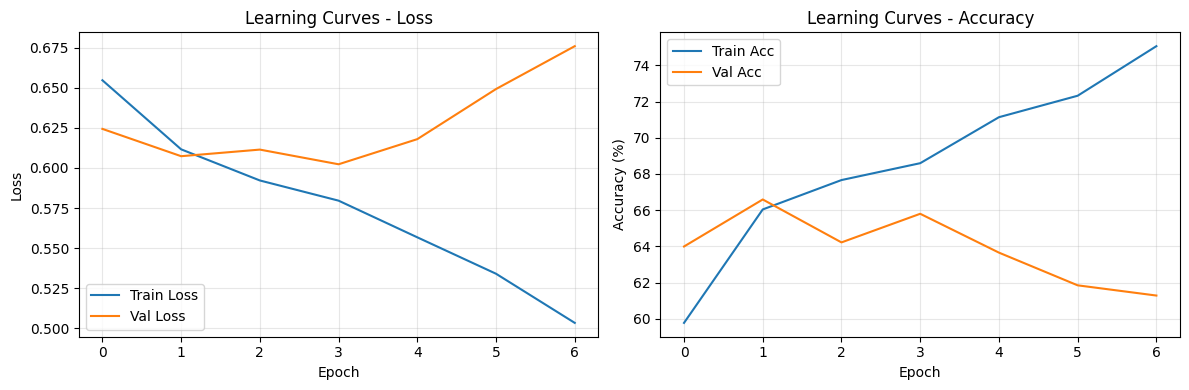

In [ ]:
# Create DataLoaders
batch_size = 32
train_dataset = TensorDataset(X_train, y_train)
val_dataset = TensorDataset(X_val, y_val)
test_dataset = TensorDataset(X_test, y_test)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size)
test_loader = DataLoader(test_dataset, batch_size=batch_size)

# Initialize model
baseline_mlp = MLPClassifier(input_dim=384, hidden_dim=128, num_layers=2, dropout=0.3)

# Loss and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(baseline_mlp.parameters(), lr=0.001)

# Train
print("Training baseline MLP (without early stopping)...")
history, best_val_acc = train_mlp(
    baseline_mlp, train_loader, val_loader,
    optimizer, criterion, num_epochs=30, device=device,
    wandb_log=False, early_stopping=True
)

# Evaluate
test_acc, _, _ = evaluate_model(baseline_mlp, test_loader, device)
print(f"\nBaseline MLP Results:")
print(f"  Best Val Accuracy: {best_val_acc:.2f}%")
print(f"  Test Accuracy: {test_acc:.2f}%")

# Plot learning curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(history['train_loss'], label='Train Loss')
ax1.plot(history['val_loss'], label='Val Loss')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.set_title('Learning Curves - Loss')
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(history['train_acc'], label='Train Acc')
ax2.plot(history['val_acc'], label='Val Acc')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy (%)')
ax2.set_title('Learning Curves - Accuracy')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Step 1.5: Hyperparameter Optimization with Optuna + wandb

In [ ]:
wandb.login()  # You'll need to login on first use

# Define objective function for Optuna
def objective(trial):
    """
    Optuna objective function

    Search space:
    - hidden_dim: Size of hidden layers
    - num_layers: Number of hidden layers
    - dropout: Dropout probability
    - learning_rate: Learning rate for optimizer
    """

    # Suggest hyperparameters
    hidden_dim = trial.suggest_int('hidden_dim', 64, 256, step=64)
    num_layers = trial.suggest_int('num_layers', 1, 3)
    dropout = trial.suggest_float('dropout', 0.1, 0.5, step=0.25)
    lr = trial.suggest_float('lr', 1e-4, 1e-2, log=True)

    # Fixed batch size
    batch_size = 32

    # Initialize wandb run
    run = wandb.init(
        project="security-analytics-mlp",
        name=f"trial_{trial.number}",
        config={
            'hidden_dim': hidden_dim,
            'num_layers': num_layers,
            'dropout': dropout,
            'lr': lr,
            'batch_size': batch_size,
            'model': 'MLP',
            'embedding': 'SentenceBERT'
        },
        reinit=True
    )

    # Create data loaders with fixed batch size
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=batch_size)

    # Initialize model
    model = MLPClassifier(
        input_dim=384,
        hidden_dim=hidden_dim,
        num_layers=num_layers,
        dropout=dropout
    )

    # Optimizer and criterion
    optimizer = optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()

    history, best_val_acc = train_mlp(
        model, train_loader, val_loader,
        optimizer, criterion, num_epochs=20,
        device=device, wandb_log=True, trial=trial,
        early_stopping=False  # Disabled to let Optuna's pruner work
    )

    # Log best validation accuracy
    wandb.log({'best_val_acc': best_val_acc})
    wandb.finish()

    return best_val_acc

# Create Optuna study with TPE sampler and Hyperband pruner
sampler = optuna.samplers.TPESampler(
    seed=SEED,
    n_startup_trials=5,  # Use random sampling for first 5 trials
    multivariate=True    # Use multivariate TPE for better performance
)

# Hyperband pruner for early stopping of unpromising trials
pruner = optuna.pruners.HyperbandPruner(
    min_resource=1,          # Minimum epochs before pruning
    max_resource=20,         # Maximum epochs (matches num_epochs in training)
    reduction_factor=3       # Aggressiveness of pruning
)

study = optuna.create_study(
    direction='maximize',
    study_name='mlp_optimization',
    sampler=sampler,
    pruner=pruner
)

# Run optimization
study.optimize(objective, n_trials=10, show_progress_bar=True)

<IPython.core.display.Javascript object>

wandb: Logging into wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: You can find your API key in your browser here: https://wandb.ai/authorize
wandb: Paste an API key from your profile and hit enter:

 ··········


wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: bryantuck to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
[I 2025-10-28 22:03:15,235] A new study created in memory with name: mlp_optimization


  0%|          | 0/10 [00:00<?, ?it/s]

wandb: WARNING Using a boolean value for 'reinit' is deprecated. Use 'return_previous' or 'finish_previous' instead.


... (18 outputs left out)

epoch,▁▃▆█
train_acc,▁▄▇█
train_loss,█▇▄▁
val_acc,▁▅▇█
val_loss,█▆▄▁
epoch,3
train_acc,62.06264
train_loss,0.6537
val_acc,62.41535
val_loss,0.6466


  [Pruned] Trial 8 stopped at epoch 4
[I 2025-10-28 22:04:23,247] Trial 8 pruned. 


epoch,▁▃▆█
train_acc,▁▆▇█
train_loss,█▄▂▁
val_acc,▁▁█▄
val_loss,█▅▄▁
epoch,3
train_acc,68.60892
train_loss,0.57717
val_acc,65.23702
val_loss,0.60027


  [Pruned] Trial 9 stopped at epoch 2
[I 2025-10-28 22:04:27,219] Trial 9 pruned. 


In [ ]:
print("\n" + "=" * 70)
print("OPTIMIZATION RESULTS")
print("=" * 70)
print(f"\nBest trial: {study.best_trial.number}")
print(f"Best validation accuracy: {study.best_value:.2f}%")
print("\nBest hyperparameters:")
for key, value in study.best_params.items():
    print(f"  {key}: {value}")


OPTIMIZATION RESULTS

Best trial: 4
Best validation accuracy: 67.38%

Best hyperparameters:
  hidden_dim: 128
  num_layers: 2
  dropout: 0.1
  lr: 0.0003823475224675188


In [ ]:
# Print pruning statistics
pruned_trials = [t for t in study.trials if t.state == optuna.trial.TrialState.PRUNED]
complete_trials = [t for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE]
print(f"\nPruning statistics:")
print(f"  Complete trials: {len(complete_trials)}")
print(f"  Pruned trials: {len(pruned_trials)}")
print(f"  Pruning rate: {len(pruned_trials)/len(study.trials)*100:.1f}%")
if pruned_trials:
    avg_pruned_epoch = sum([len(t.intermediate_values) for t in pruned_trials]) / len(pruned_trials)
    print(f"  Average epoch when pruned: {avg_pruned_epoch:.1f}")
    print(f"  Time saved: Stopped {len(pruned_trials)} unpromising trials early")


Pruning statistics:
  Complete trials: 3
  Pruned trials: 7
  Pruning rate: 70.0%
  Average epoch when pruned: 3.4
  Time saved: Stopped 7 unpromising trials early


In [ ]:
# Visualize optimization history
fig = optuna.visualization.plot_optimization_history(study)
fig.show()

fig = optuna.visualization.plot_param_importances(study)
fig.show()

## Step 1.6: Train Final MLP with Best Hyperparameters

In [ ]:
# Initialize wandb for final run
wandb.init(
    project="security-analytics-mlp",
    name="final_model",
    config=study.best_params
)

# Create model with best params
best_params = study.best_params
best_mlp = MLPClassifier(
    input_dim=384,
    hidden_dim=best_params['hidden_dim'],
    num_layers=best_params['num_layers'],
    dropout=best_params['dropout']
)

# Create data loaders with fixed batch size
batch_size = 32
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size)
test_loader = DataLoader(test_dataset, batch_size=batch_size)

# Optimizer and criterion
optimizer = optim.Adam(best_mlp.parameters(), lr=best_params['lr'])
criterion = nn.CrossEntropyLoss()

# Train
print("Training with early stopping enabled (patience=5, min_delta=0.001)...")
history, best_val_acc = train_mlp(
    best_mlp, train_loader, val_loader,
    optimizer, criterion, num_epochs=30,
    device=device, wandb_log=True,
    early_stopping=True, patience=5, min_delta=0.001
)

# Evaluate on test set
test_acc, test_preds, test_labels = evaluate_model(best_mlp, test_loader, device)

print(f"\nFinal MLP Results:")
print(f"  Best Val Accuracy: {best_val_acc:.2f}%")
print(f"  Test Accuracy: {test_acc:.2f}%")

# Log final metrics to wandb
wandb.log({
    'final_test_acc': test_acc,
    'final_best_val_acc': best_val_acc
})

epoch,▁█
train_acc,▁█
train_loss,█▁
val_acc,▁█
val_loss,█▁
epoch,1
train_acc,59.42438
train_loss,0.68112
val_acc,59.48081
val_loss,0.67594


Training with early stopping enabled (patience=5, min_delta=0.001)...
Epoch [5/30] Train Loss: 0.5705, Train Acc: 69.65% | Val Loss: 0.6004, Val Acc: 66.37%
  [Early Stopping] No improvement for 5 epochs. Stopping at epoch 8
  Best validation accuracy: 67.04%

Final MLP Results:
  Best Val Accuracy: 67.04%
  Test Accuracy: 64.33%


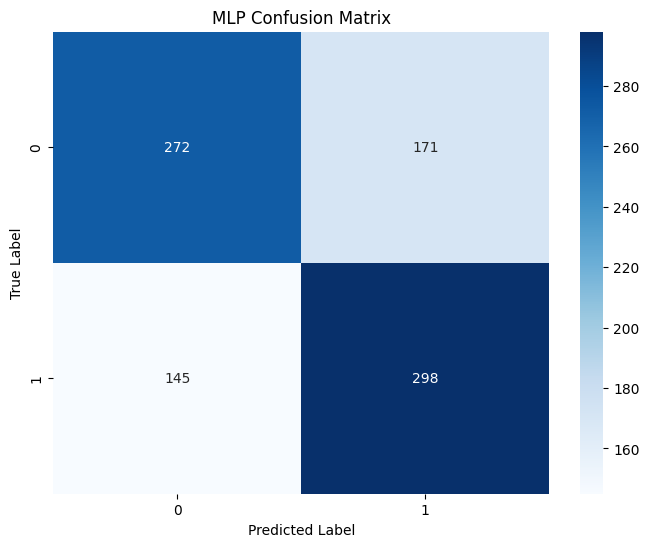


Classification Report:
              precision    recall  f1-score   support

     Class 0       0.65      0.61      0.63       443
     Class 1       0.64      0.67      0.65       443

    accuracy                           0.64       886
   macro avg       0.64      0.64      0.64       886
weighted avg       0.64      0.64      0.64       886



epoch,▁▂▃▄▅▆▇█
final_best_val_acc,▁
final_test_acc,▁
train_acc,▁▄▅▅▆▆▇█
train_loss,█▆▅▄▄▃▂▁
val_acc,▅▆█▇▇▇▄▁
val_loss,▆▃▁▂▁▁▄█
epoch,7
final_best_val_acc,67.04289
final_test_acc,64.33409
train_acc,75.95937



Part 1 Complete!


In [ ]:
# Create and log confusion matrix
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

cm = confusion_matrix(test_labels, test_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('MLP Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
wandb.log({"confusion_matrix": wandb.Image(plt)})
plt.show()

# Log classification report
print("\nClassification Report:")
print(classification_report(test_labels, test_preds, target_names=['Class 0', 'Class 1']))

wandb.finish()

print("\nPart 1 Complete!")
print("=" * 70)

# Save the results for comparison later
part1_results = {
    'model': 'MLP',
    'embedding': 'SentenceBERT (MiniLM-L6)',
    'test_acc': test_acc,
    'best_val_acc': best_val_acc,
    'params': best_params
}

# PART 2: TOKEN EMBEDDINGS + LSTM


## Step 2.1: Prepare Token-level Embeddings

In [ ]:
import gensim.downloader as api
print("\nDownloading GloVe embeddings (this may take a few minutes on first run)...")
glove_model = api.load('glove-wiki-gigaword-100')
print(f"GloVe model loaded successfully")
print(f"  Model: glove-wiki-gigaword-100")
print(f"  Embedding dimension: {glove_model.vector_size}")
print(f"  Vocabulary size: {len(glove_model):,} words")


[==================================================] 100.0% 128.1/128.1MB downloaded
GloVe model loaded successfully
  Model: glove-wiki-gigaword-100
  Embedding dimension: 100
  Vocabulary size: 400,000 words


In [ ]:
# Test the embeddings
print("\nExample GloVe embeddings:")
for word in ['security', 'computer', 'network']:
    if word in glove_model:
        print(f"  '{word}': shape {glove_model[word].shape}")


Example GloVe embeddings:
  'security': shape (100,)
  'computer': shape (100,)
  'network': shape (100,)


## Step 2.2: Build Vocabulary and Embedding Matrix

In [ ]:
# Simple tokenizer
from collections import Counter
import re

def simple_tokenize(text):
    """Simple word tokenizer - lowercase and split on word boundaries"""
    return re.findall(r'\b\w+\b', text.lower())

# Build vocabulary from training data
all_tokens = []
for text in train_texts:
    all_tokens.extend(simple_tokenize(text))

vocab_counter = Counter(all_tokens)
print(f"Total tokens in training data: {len(all_tokens):,}")
print(f"Unique tokens: {len(vocab_counter):,}")

# Create vocabulary (most common words + special tokens)
vocab_size = 10000  # Limit vocabulary size
special_tokens = {'<PAD>': 0, '<UNK>': 1}
word_to_idx = special_tokens.copy()

# Add most common words
for word, _ in vocab_counter.most_common(vocab_size - len(special_tokens)):
    if word not in word_to_idx:
        word_to_idx[word] = len(word_to_idx)

print(f"Final vocabulary size: {len(word_to_idx):,}")

# Create embedding matrix initialized with GloVe vectors
import numpy as np

embedding_dim = glove_model.vector_size
embedding_matrix = np.zeros((len(word_to_idx), embedding_dim))

# Fill embedding matrix
oov_count = 0
for word, idx in word_to_idx.items():
    if word in special_tokens:
        # Random initialization for special tokens
        embedding_matrix[idx] = np.random.normal(0, 0.1, embedding_dim)
    elif word in glove_model:
        embedding_matrix[idx] = glove_model[word]
    else:
        # Random initialization for out-of-vocabulary words
        embedding_matrix[idx] = np.random.normal(0, 0.1, embedding_dim)
        oov_count += 1

coverage = (len(word_to_idx) - oov_count - len(special_tokens)) / (len(word_to_idx) - len(special_tokens)) * 100
print(f"GloVe coverage: {coverage:.1f}% ({len(word_to_idx) - oov_count - len(special_tokens):,} words found)")
print(f"Out-of-vocabulary words: {oov_count:,}")
print(f"Embedding matrix shape: {embedding_matrix.shape}")


Total tokens in training data: 108,181
Unique tokens: 12,027
Final vocabulary size: 10,000
GloVe coverage: 85.9% (8,590 words found)
Out-of-vocabulary words: 1,408
Embedding matrix shape: (10000, 100)


## Step 2.3: Create Dataset for LSTM with GloVe


In [ ]:
class TextDatasetForLSTM(Dataset):
    """
    Dataset that converts text to word indices for GloVe embedding lookup
    """
    def __init__(self, texts, labels, word_to_idx, max_length=128):
        self.texts = texts
        self.labels = labels
        self.word_to_idx = word_to_idx
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        text = self.texts[idx]
        label = self.labels[idx]

        # Tokenize and convert to indices
        tokens = simple_tokenize(text)
        indices = [self.word_to_idx.get(token, self.word_to_idx['<UNK>'])
                   for token in tokens]

        # Pad or truncate to max_length
        if len(indices) < self.max_length:
            indices = indices + [self.word_to_idx['<PAD>']] * (self.max_length - len(indices))
        else:
            indices = indices[:self.max_length]

        return {
            'input_ids': torch.tensor(indices, dtype=torch.long),
            'label': torch.tensor(label, dtype=torch.long)
        }

# Create datasets
print("\n[2.3] Creating datasets for LSTM...")
train_dataset_lstm = TextDatasetForLSTM(train_texts, train_labels, word_to_idx)
val_dataset_lstm = TextDatasetForLSTM(val_texts, val_labels, word_to_idx)
test_dataset_lstm = TextDatasetForLSTM(test_texts, test_labels, word_to_idx)

print(f"Datasets created")
print(f"  Train: {len(train_dataset_lstm)} samples")
print(f"  Val: {len(val_dataset_lstm)} samples")
print(f"  Test: {len(test_dataset_lstm)} samples")

# Test dataset
sample = train_dataset_lstm[0]
print(f"\nSample data:")
print(f"  Input IDs shape: {sample['input_ids'].shape}")
print(f"  First 10 indices: {sample['input_ids'][:10].tolist()}")
print(f"  Label: {sample['label']}")


[2.3] Creating datasets for LSTM...
Datasets created
  Train: 7088 samples
  Val: 886 samples
  Test: 886 samples

Sample data:
  Input IDs shape: torch.Size([128])
  First 10 indices: [78, 503, 5, 201, 111, 78, 458, 81, 41, 5]
  Label: 0


## Step 2.4: Define LSTM Model with GloVe Embeddings


In [ ]:
class LSTMClassifier(nn.Module):
    """
    LSTM-based text classifier with GloVe embeddings

    Architecture:
    - Embedding layer (initialized with GloVe, can be frozen or fine-tuned)
    - Bidirectional LSTM
    - Fully connected output layer

    Key difference from transformers: embeddings are STATIC (not contextualized)
    Each word always has the same vector, regardless of context
    """
    def __init__(self, vocab_size, embedding_dim=100, embedding_matrix=None,
                 hidden_dim=128, num_layers=2, dropout=0.3,
                 bidirectional=True, freeze_embeddings=True):
        super(LSTMClassifier, self).__init__()

        # Embedding layer
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        if embedding_matrix is not None:
            # Initialize with pre-trained GloVe vectors
            self.embedding.weight.data.copy_(torch.from_numpy(embedding_matrix))
        if freeze_embeddings:
            # Freeze embeddings (treat as fixed features)
            self.embedding.weight.requires_grad = False

        # LSTM
        self.lstm = nn.LSTM(
            embedding_dim, hidden_dim, num_layers=num_layers,
            dropout=dropout if num_layers > 1 else 0,
            bidirectional=bidirectional, batch_first=True
        )

        # Output layer
        lstm_output_dim = hidden_dim * 2 if bidirectional else hidden_dim
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(lstm_output_dim, 2)

    def forward(self, input_ids):
        # Get static GloVe embeddings (same for every context)
        embeddings = self.embedding(input_ids)  # Shape: (batch, seq_len, embedding_dim)

        # LSTM forward pass
        lstm_out, (hidden, cell) = self.lstm(embeddings)

        # Use the last hidden state (from both directions if bidirectional)
        if self.lstm.bidirectional:
            # Concatenate the final forward and backward hidden states
            hidden = torch.cat((hidden[-2], hidden[-1]), dim=1)
        else:
            hidden = hidden[-1]

        # Dropout and classification
        output = self.dropout(hidden)
        output = self.fc(output)

        return output

# Test the model
print("\n[2.4] Testing LSTM architecture...")
test_lstm = LSTMClassifier(
    vocab_size=len(word_to_idx),
    embedding_dim=embedding_dim,
    embedding_matrix=embedding_matrix,
    hidden_dim=128,
    num_layers=2,
    dropout=0.3,
    bidirectional=True,
    freeze_embeddings=True
)
test_lstm.to(device)

# Test with sample batch
sample_batch = next(iter(DataLoader(train_dataset_lstm, batch_size=4)))
test_output = test_lstm(sample_batch['input_ids'].to(device))
print(f"LSTM model test output shape: {test_output.shape}")

# Count parameters
trainable_params = sum(p.numel() for p in test_lstm.parameters() if p.requires_grad)
frozen_params = sum(p.numel() for p in test_lstm.parameters() if not p.requires_grad)
print(f"  Trainable parameters: {trainable_params:,}")
print(f"  Frozen parameters (GloVe embeddings): {frozen_params:,}")
print(f"  Total parameters: {trainable_params + frozen_params:,}")


[2.4] Testing LSTM architecture...
LSTM model test output shape: torch.Size([4, 2])
  Trainable parameters: 631,298
  Frozen parameters (GloVe embeddings): 1,000,000
  Total parameters: 1,631,298


## Step 2.5: Training Function for LSTM


In [ ]:
def train_lstm(model, train_loader, val_loader, optimizer, criterion,
               num_epochs, device, wandb_log=False, patience=3):
    """
    Training loop for LSTM model with early stopping

    Args:
        patience: Number of epochs to wait for improvement before stopping
    """
    model.to(device)
    history = {
        'train_loss': [],
        'train_acc': [],
        'val_loss': [],
        'val_acc': []
    }

    best_val_acc = 0.0
    best_model_state = None
    epochs_without_improvement = 0

    for epoch in range(num_epochs):
        # Training phase
        model.train()
        train_loss = 0.0
        train_correct = 0
        train_total = 0

        progress_bar = tqdm(train_loader, desc=f'Epoch {epoch+1}/{num_epochs}')
        for batch in progress_bar:
            input_ids = batch['input_ids'].to(device)
            labels = batch['label'].to(device)

            # Forward pass
            outputs = model(input_ids)
            loss = criterion(outputs, labels)

            # Backward pass
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            # Metrics
            train_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            train_total += labels.size(0)
            train_correct += (predicted == labels).sum().item()

            # Update progress bar
            progress_bar.set_postfix({'loss': loss.item()})

        train_loss = train_loss / len(train_loader)
        train_acc = 100 * train_correct / train_total

        # Validation phase
        model.eval()
        val_loss = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():
            for batch in val_loader:
                input_ids = batch['input_ids'].to(device)
                labels = batch['label'].to(device)

                outputs = model(input_ids)
                loss = criterion(outputs, labels)

                val_loss += loss.item()
                _, predicted = torch.max(outputs.data, 1)
                val_total += labels.size(0)
                val_correct += (predicted == labels).sum().item()

        val_loss = val_loss / len(val_loader)
        val_acc = 100 * val_correct / val_total

        # Save history
        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)

        # Log to wandb
        if wandb_log:
            wandb.log({
                'epoch': epoch,
                'train_loss': train_loss,
                'train_acc': train_acc,
                'val_loss': val_loss,
                'val_acc': val_acc
            })

        # Track best model
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_model_state = model.state_dict().copy()
            epochs_without_improvement = 0
            print(f"  => New best validation accuracy: {best_val_acc:.2f}%")
        else:
            epochs_without_improvement += 1
            print(f"  => No improvement for {epochs_without_improvement} epoch(s)")

        # Early stopping check
        if epochs_without_improvement >= patience:
            print(f"\n[!] Early stopping triggered after {epoch+1} epochs")
            print(f"   Best validation accuracy: {best_val_acc:.2f}%")
            # Restore best model
            if best_model_state is not None:
                model.load_state_dict(best_model_state)
            break

        # Print epoch summary
        print(f"Epoch [{epoch+1}/{num_epochs}] "
              f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}% | "
              f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.2f}%")

    return history, best_val_acc

def evaluate_lstm(model, test_loader, device):
    """Evaluate LSTM model on test set"""
    model.eval()
    test_correct = 0
    test_total = 0
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for batch in test_loader:
            input_ids = batch['input_ids'].to(device)
            labels = batch['label'].to(device)

            outputs = model(input_ids)
            _, predicted = torch.max(outputs.data, 1)

            test_total += labels.size(0)
            test_correct += (predicted == labels).sum().item()

            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    test_acc = 100 * test_correct / test_total
    return test_acc, all_preds, all_labels

## Step 2.6: Train LSTM Model


In [ ]:
# Initialize wandb
wandb.init(
    project="security-analytics-lstm",
    name="lstm_glove",
    config={
        'model': 'LSTM',
        'embedding': 'GloVe-100d (frozen)',
        'vocab_size': len(word_to_idx),
        'embedding_dim': embedding_dim,
        'hidden_dim': 128,
        'num_layers': 2,
        'dropout': 0.3,
        'bidirectional': True,
        'lr': 0.001,
        'batch_size': 32
    }
)

# Create data loaders
batch_size = 32
train_loader_lstm = DataLoader(train_dataset_lstm, batch_size=batch_size, shuffle=True)
val_loader_lstm = DataLoader(val_dataset_lstm, batch_size=batch_size)
test_loader_lstm = DataLoader(test_dataset_lstm, batch_size=batch_size)

# Initialize model
lstm_model = LSTMClassifier(
    vocab_size=len(word_to_idx),
    embedding_dim=embedding_dim,
    embedding_matrix=embedding_matrix,
    hidden_dim=128,
    num_layers=2,
    dropout=0.3,
    bidirectional=True,
    freeze_embeddings=True
)

# Optimizer and criterion
optimizer = optim.Adam(lstm_model.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()

# Train
print("\nTraining LSTM with GloVe embeddings...")
print("Early stopping enabled with patience=3")
history_lstm, best_val_acc_lstm = train_lstm(
    lstm_model, train_loader_lstm, val_loader_lstm,
    optimizer, criterion, num_epochs=20,
    device=device, wandb_log=True, patience=3
)

# Evaluate on test set
test_acc_lstm, test_preds_lstm, test_labels_lstm = evaluate_lstm(
    lstm_model, test_loader_lstm, device
)

print(f"\nLSTM Results:")
print(f"  Best Val Accuracy: {best_val_acc_lstm:.2f}%")
print(f"  Test Accuracy: {test_acc_lstm:.2f}%")

# Log metrics to wandb
wandb.log({
    'final_test_acc': test_acc_lstm,
    'final_best_val_acc': best_val_acc_lstm
})


Training LSTM with GloVe embeddings...
Early stopping enabled with patience=3


Epoch 1/20:   0%|          | 0/222 [00:00<?, ?it/s]

  => New best validation accuracy: 58.01%
Epoch [1/20] Train Loss: 0.6578, Train Acc: 58.94% | Val Loss: 0.6455, Val Acc: 58.01%


Epoch 2/20:   0%|          | 0/222 [00:00<?, ?it/s]

  => New best validation accuracy: 68.06%
Epoch [2/20] Train Loss: 0.6155, Train Acc: 64.38% | Val Loss: 0.5894, Val Acc: 68.06%


Epoch 3/20:   0%|          | 0/222 [00:00<?, ?it/s]

... (13 outputs left out)

Epoch 10/20:   0%|          | 0/222 [00:00<?, ?it/s]

  => No improvement for 2 epoch(s)
Epoch [10/20] Train Loss: 0.3947, Train Acc: 81.14% | Val Loss: 0.6889, Val Acc: 68.51%


Epoch 11/20:   0%|          | 0/222 [00:00<?, ?it/s]

  => No improvement for 3 epoch(s)

[!] Early stopping triggered after 11 epochs
   Best validation accuracy: 71.44%

LSTM Results:
  Best Val Accuracy: 71.44%
  Test Accuracy: 69.19%


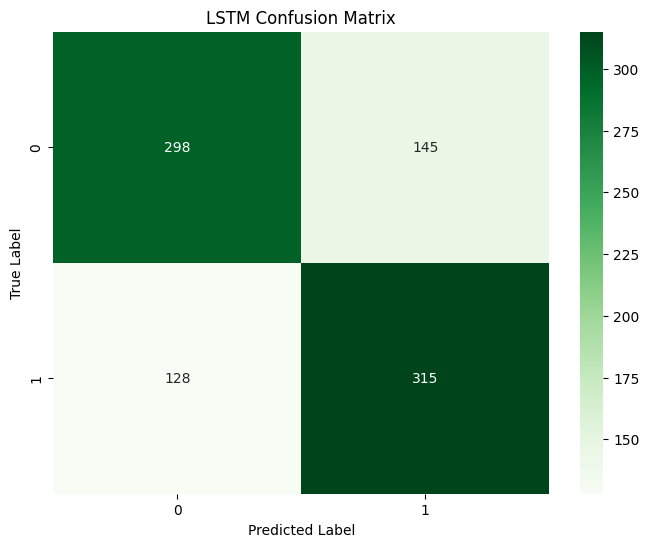


Classification Report:
              precision    recall  f1-score   support

     Class 0       0.70      0.67      0.69       443
     Class 1       0.68      0.71      0.70       443

    accuracy                           0.69       886
   macro avg       0.69      0.69      0.69       886
weighted avg       0.69      0.69      0.69       886



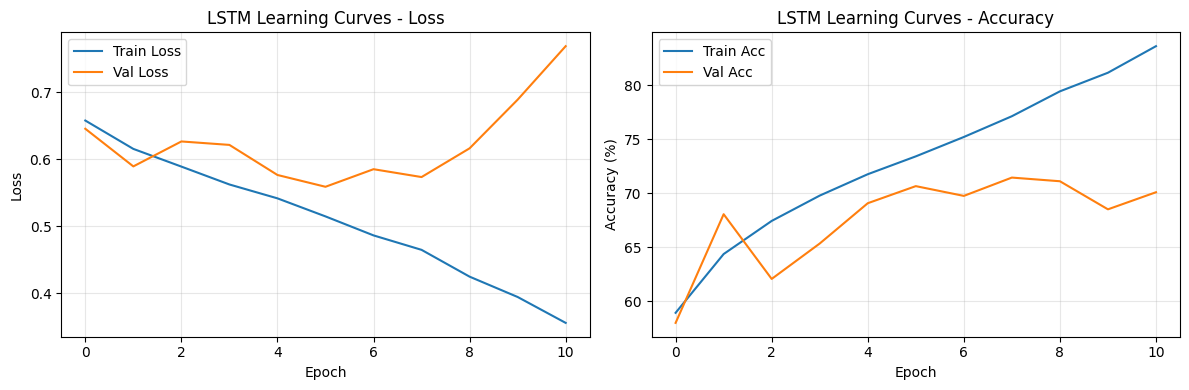

epoch,▁▂▂▃▄▅▅▆▇▇█
final_best_val_acc,▁
final_test_acc,▁
train_acc,▁▃▃▄▅▅▆▆▇▇█
train_loss,█▇▆▆▅▅▄▄▃▂▁
val_acc,▁▆▃▅▇█▇██▆▇
val_loss,▄▂▃▃▂▁▂▁▃▅█
epoch,10
final_best_val_acc,71.4447
final_test_acc,69.18736
train_acc,83.59199



Part 2 Complete!


In [ ]:
# Confusion matrix
cm_lstm = confusion_matrix(test_labels_lstm, test_preds_lstm)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_lstm, annot=True, fmt='d', cmap='Greens')
plt.title('LSTM Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
wandb.log({"confusion_matrix": wandb.Image(plt)})
plt.show()

# Classification report
print("\nClassification Report:")
print(classification_report(test_labels_lstm, test_preds_lstm,
                           target_names=['Class 0', 'Class 1']))

# Plot learning curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(history_lstm['train_loss'], label='Train Loss')
ax1.plot(history_lstm['val_loss'], label='Val Loss')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.set_title('LSTM Learning Curves - Loss')
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(history_lstm['train_acc'], label='Train Acc')
ax2.plot(history_lstm['val_acc'], label='Val Acc')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy (%)')
ax2.set_title('LSTM Learning Curves - Accuracy')
ax2.legend()
ax2.grid(True, alpha=0.3)

wandb.log({"learning_curves": wandb.Image(plt)})
plt.tight_layout()
plt.show()

wandb.finish()

# Save results
part2_results = {
    'model': 'LSTM',
    'embedding': 'GloVe-100d (frozen)',
    'test_acc': test_acc_lstm,
    'best_val_acc': best_val_acc_lstm,
    'trainable_params': trainable_params
}

print("\nPart 2 Complete!")
print("=" * 70)

# PART 3: FINE-TUNING TRANSFORMERS (RoBERTa)


## Step 3.1: Prepare Data for HuggingFace Trainer

In [ ]:
# Load RoBERTa tokenizer
roberta_tokenizer = AutoTokenizer.from_pretrained('roberta-base')

# Tokenize datasets
def tokenize_function(examples):
    return roberta_tokenizer(
        examples['text'],
        padding='max_length',
        truncation=True,
        max_length=128
    )

print("Tokenizing datasets...")
tokenized_train = dataset['train'].map(tokenize_function, batched=True)
tokenized_val = dataset['validation'].map(tokenize_function, batched=True)
tokenized_test = dataset['test'].map(tokenize_function, batched=True)

# Set format for PyTorch
tokenized_train.set_format('torch', columns=['input_ids', 'attention_mask', 'label'])
tokenized_val.set_format('torch', columns=['input_ids', 'attention_mask', 'label'])
tokenized_test.set_format('torch', columns=['input_ids', 'attention_mask', 'label'])

print(f"Datasets tokenized and formatted")
print(f"  Train: {len(tokenized_train)} samples")
print(f"  Val: {len(tokenized_val)} samples")
print(f"  Test: {len(tokenized_test)} samples")

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Tokenizing datasets...


Map:   0%|          | 0/7088 [00:00<?, ? examples/s]

Map:   0%|          | 0/886 [00:00<?, ? examples/s]

Map:   0%|          | 0/886 [00:00<?, ? examples/s]

Datasets tokenized and formatted
  Train: 7088 samples
  Val: 886 samples
  Test: 886 samples


## Step 3.2: Load RoBERTa Model

In [ ]:
roberta_model = AutoModelForSequenceClassification.from_pretrained(
    'roberta-base',
    num_labels=2
)

# Count parameters
total_params = sum(p.numel() for p in roberta_model.parameters())
trainable_params_roberta = sum(p.numel() for p in roberta_model.parameters() if p.requires_grad)

print(f"RoBERTa model loaded")
print(f"  Total parameters: {total_params:,}")
print(f"  Trainable parameters: {trainable_params_roberta:,}")

model.safetensors:   0%|          | 0.00/499M [00:00<?, ?B/s]

Some weights of RobertaForSequenceClassification were not initialized from the model checkpoint at roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


RoBERTa model loaded
  Total parameters: 124,647,170
  Trainable parameters: 124,647,170


## Step 3.3: Define Training Arguments

In [ ]:
training_args = TrainingArguments(
    output_dir='./results_roberta',
    eval_strategy='epoch',
    save_strategy='epoch',
    learning_rate=2e-5,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=32,
    num_train_epochs=5,
    weight_decay=0.01,
    fp16=True,  # Mixed precision training for faster training
    load_best_model_at_end=True,
    metric_for_best_model='accuracy',
    greater_is_better=True,  # Higher accuracy is better
    logging_dir='./logs',
    logging_steps=50,
    warmup_steps=100,
    save_total_limit=2,
    report_to='wandb',
    run_name='roberta-machine-text-detection'
)

print(" Training arguments configured")

 Training arguments configured


## Step 3.4: Define Metrics

In [ ]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

def compute_metrics(eval_pred):
    """Compute metrics for evaluation"""
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    accuracy = accuracy_score(labels, predictions)
    precision, recall, f1, _ = precision_recall_fscore_support(
        labels, predictions, average='binary'
    )

    return {
        'accuracy': accuracy,
        'precision': precision,
        'recall': recall,
        'f1': f1
    }

## Step 3.5: Initialize Trainer and Train

In [ ]:
# Initialize wandb for this run
wandb.init(
    project="security-analytics-roberta",
    name="roberta-base-finetuned",
    config={
        'model': 'roberta-base',
        'task': 'disinformation-detection',
        'learning_rate': training_args.learning_rate,
        'batch_size': training_args.per_device_train_batch_size,
        'epochs': training_args.num_train_epochs
    }
)

# Initialize Trainer
trainer = Trainer(
    model=roberta_model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_val,
    tokenizer=roberta_tokenizer,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)]
)

# Train the model
print("\nStarting RoBERTa fine-tuning...")
print("This may take 10-20 minutes depending on your GPU...")
train_result = trainer.train()

print("\nTraining complete!")


Starting RoBERTa fine-tuning...
This may take 10-20 minutes depending on your GPU...


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.551000,0.619186,0.681716,0.622155,0.925508,0.744102
2,0.462700,0.593796,0.742664,0.701689,0.844244,0.766393
3,0.395500,0.569025,0.749436,0.705773,0.855530,0.773469
4,0.318300,0.770500,0.739278,0.689286,0.871332,0.769691
5,0.251600,0.912138,0.726862,0.671795,0.887133,0.764591



Training complete!


## Step 3.6: Evaluate on Test Set


RoBERTa Test Results:
  Test Accuracy: 75.06%
  Test Precision: 0.7079
  Test Recall: 0.8533
  Test F1: 0.7738


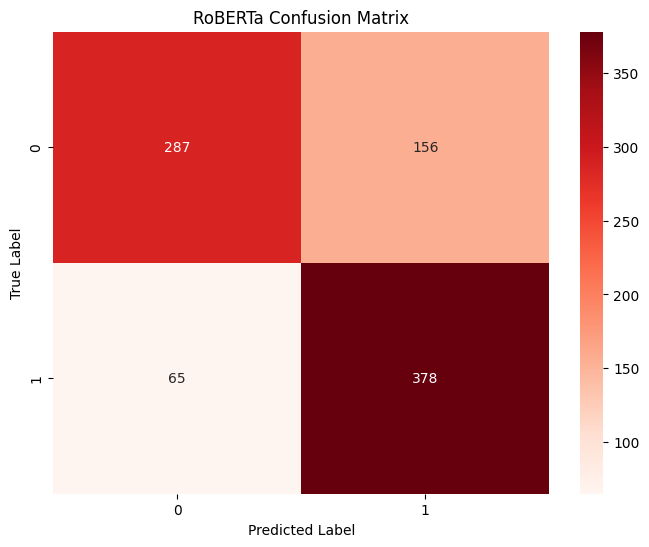


Classification Report:
              precision    recall  f1-score   support

     Class 0       0.82      0.65      0.72       443
     Class 1       0.71      0.85      0.77       443

    accuracy                           0.75       886
   macro avg       0.76      0.75      0.75       886
weighted avg       0.76      0.75      0.75       886



eval/accuracy,▁▇█▇▆█
eval/f1,▁▆█▇▆█
eval/loss,▂▂▁▅█▂
eval/precision,▁▇█▆▅█
eval/recall,█▁▂▃▅▂
eval/runtime,▇▁▂▂▃█
eval/samples_per_second,▂█▇▇▆▁
eval/steps_per_second,▂█▇▇▆▁
final_test_acc,▁
final_test_f1,▁
+13,...



Part 3 Complete!


In [ ]:
# Evaluate
test_results = trainer.evaluate(tokenized_test)

print("\nRoBERTa Test Results:")
print(f"  Test Accuracy: {test_results['eval_accuracy']*100:.2f}%")
print(f"  Test Precision: {test_results['eval_precision']:.4f}")
print(f"  Test Recall: {test_results['eval_recall']:.4f}")
print(f"  Test F1: {test_results['eval_f1']:.4f}")

# Get predictions
predictions_output = trainer.predict(tokenized_test)
predictions_roberta = np.argmax(predictions_output.predictions, axis=-1)
labels_roberta = predictions_output.label_ids

# Confusion matrix
cm_roberta = confusion_matrix(labels_roberta, predictions_roberta)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_roberta, annot=True, fmt='d', cmap='Reds')
plt.title('RoBERTa Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
wandb.log({"confusion_matrix": wandb.Image(plt)})
plt.show()

# Classification report
print("\nClassification Report:")
print(classification_report(labels_roberta, predictions_roberta,
                           target_names=['Class 0', 'Class 1']))

# Log to wandb
wandb.log({
    'final_test_acc': test_results['eval_accuracy'] * 100,
    'final_test_f1': test_results['eval_f1']
})

wandb.finish()

# Save results
part3_results = {
    'model': 'RoBERTa',
    'embedding': 'RoBERTa-base (fine-tuned)',
    'test_acc': test_results['eval_accuracy'] * 100,
    'test_f1': test_results['eval_f1'],
    'trainable_params': trainable_params_roberta
}

print("\nPart 3 Complete!")
print("=" * 70)

# PART 4: COMPARISON & ANALYSIS


In [ ]:
# Create comparison dataframe with better formatting
comparison_data = []

# MLP results
mlp_data = {
    'Model': 'MLP',
    'Embedding': 'SentenceBERT',
    'Embedding Type': 'Sentence-level',
    'Test Accuracy (%)': part1_results['test_acc'],
    'Val Accuracy (%)': part1_results['best_val_acc'],
    'Trainable Params': f"{sum(p.numel() for p in best_mlp.parameters()) / 1e6:.2f}M",
}
comparison_data.append(mlp_data)

# LSTM results
lstm_data = {
    'Model': 'LSTM',
    'Embedding': 'GloVe',
    'Embedding Type': 'Static word-level',
    'Test Accuracy (%)': part2_results['test_acc'],
    'Val Accuracy (%)': part2_results['best_val_acc'],
    'Trainable Params': f"{part2_results.get('trainable_params', 0)/1e6:.2f}M" if 'trainable_params' in part2_results else 'N/A',
}
comparison_data.append(lstm_data)

# RoBERTa results
roberta_data = {
    'Model': 'RoBERTa',
    'Embedding': 'Contextual (fine-tuned)',
    'Embedding Type': 'Contextual',
    'Test Accuracy (%)': part3_results['test_acc'],
    'Val Accuracy (%)': 'N/A',  # Not tracked in Trainer
    'Trainable Params': f"{part3_results.get('trainable_params', 0)/1e6:.1f}M" if 'trainable_params' in part3_results else 'N/A',
}
comparison_data.append(roberta_data)

comparison_df = pd.DataFrame(comparison_data)

print("\n" + "=" * 70)
print("FINAL RESULTS COMPARISON")
print("=" * 70)
print(comparison_df.to_string(index=False))

# Calculate performance gains
mlp_acc = part1_results['test_acc']
lstm_acc = part2_results['test_acc']
roberta_acc = part3_results['test_acc']

print("\n" + "=" * 70)
print("PERFORMANCE ANALYSIS")
print("=" * 70)
print(f"\nAbsolute Accuracy:")
print(f"  MLP:     {mlp_acc:.2f}%")
print(f"  LSTM:    {lstm_acc:.2f}%")
print(f"  RoBERTa: {roberta_acc:.2f}%")

print(f"\nRelative Improvements:")
print(f"  LSTM vs MLP:        +{lstm_acc - mlp_acc:.2f}% ({((lstm_acc/mlp_acc - 1) * 100):.1f}% relative gain)")
print(f"  RoBERTa vs LSTM:    +{roberta_acc - lstm_acc:.2f}% ({((roberta_acc/lstm_acc - 1) * 100):.1f}% relative gain)")
print(f"  RoBERTa vs MLP:     +{roberta_acc - mlp_acc:.2f}% ({((roberta_acc/mlp_acc - 1) * 100):.1f}% relative gain)")


FINAL RESULTS COMPARISON
  Model               Embedding    Embedding Type  Test Accuracy (%) Val Accuracy (%) Trainable Params
    MLP            SentenceBERT    Sentence-level          64.334086        67.042889            0.07M
   LSTM                   GloVe Static word-level          69.187359        71.444695            0.63M
RoBERTa Contextual (fine-tuned)        Contextual          75.056433              N/A           124.6M

PERFORMANCE ANALYSIS

Absolute Accuracy:
  MLP:     64.33%
  LSTM:    69.19%
  RoBERTa: 75.06%

Relative Improvements:
  LSTM vs MLP:        +4.85% (7.5% relative gain)
  RoBERTa vs LSTM:    +5.87% (8.5% relative gain)
  RoBERTa vs MLP:     +10.72% (16.7% relative gain)


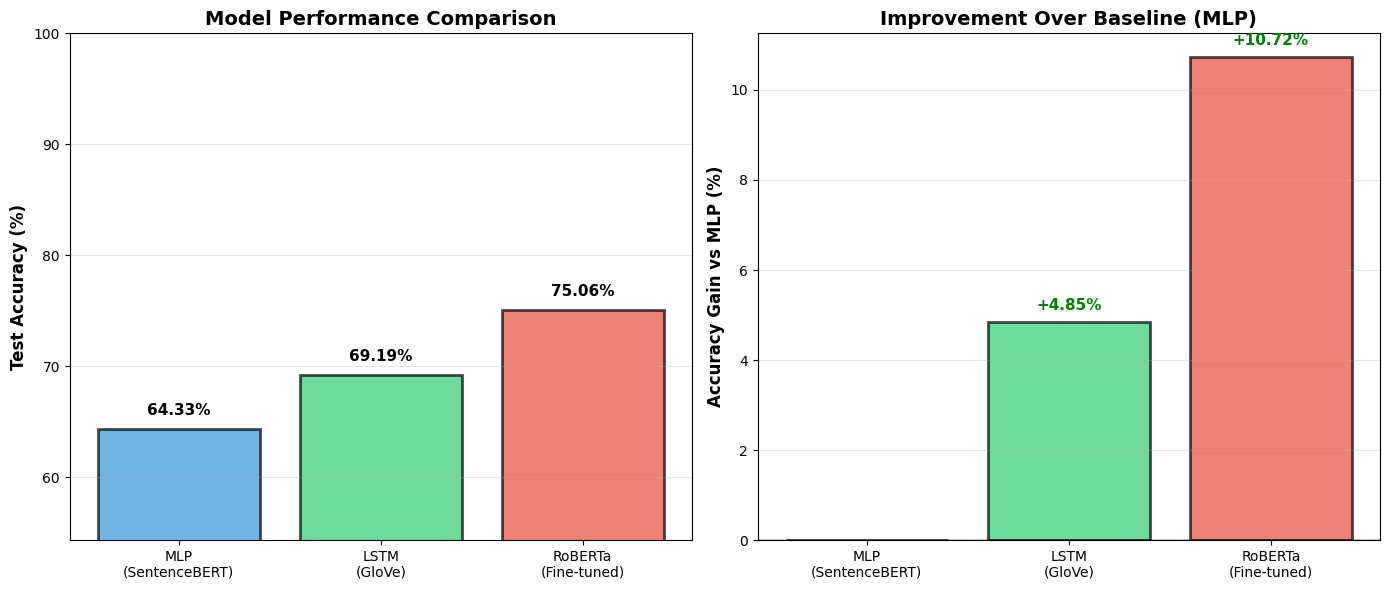

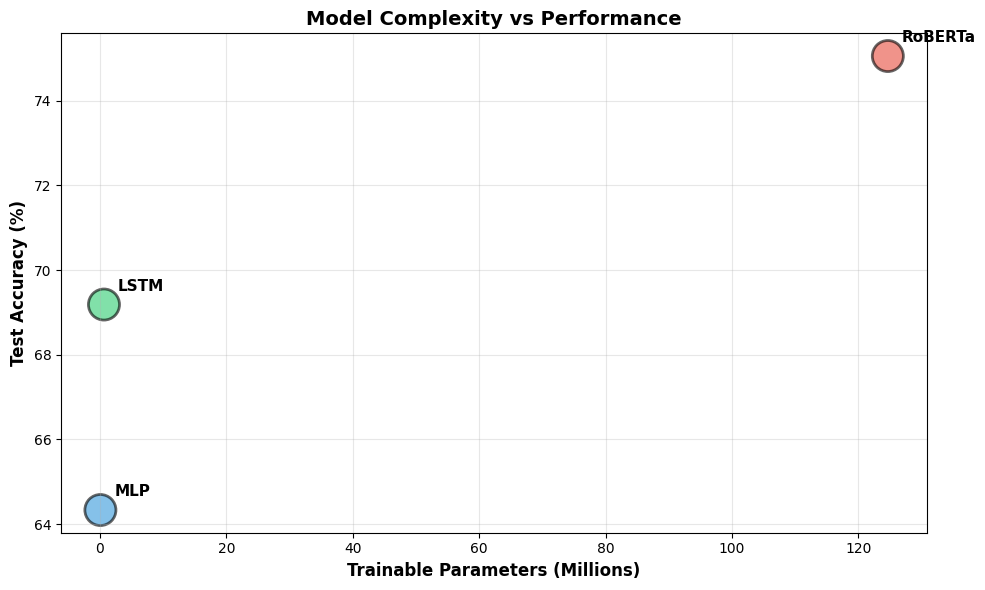

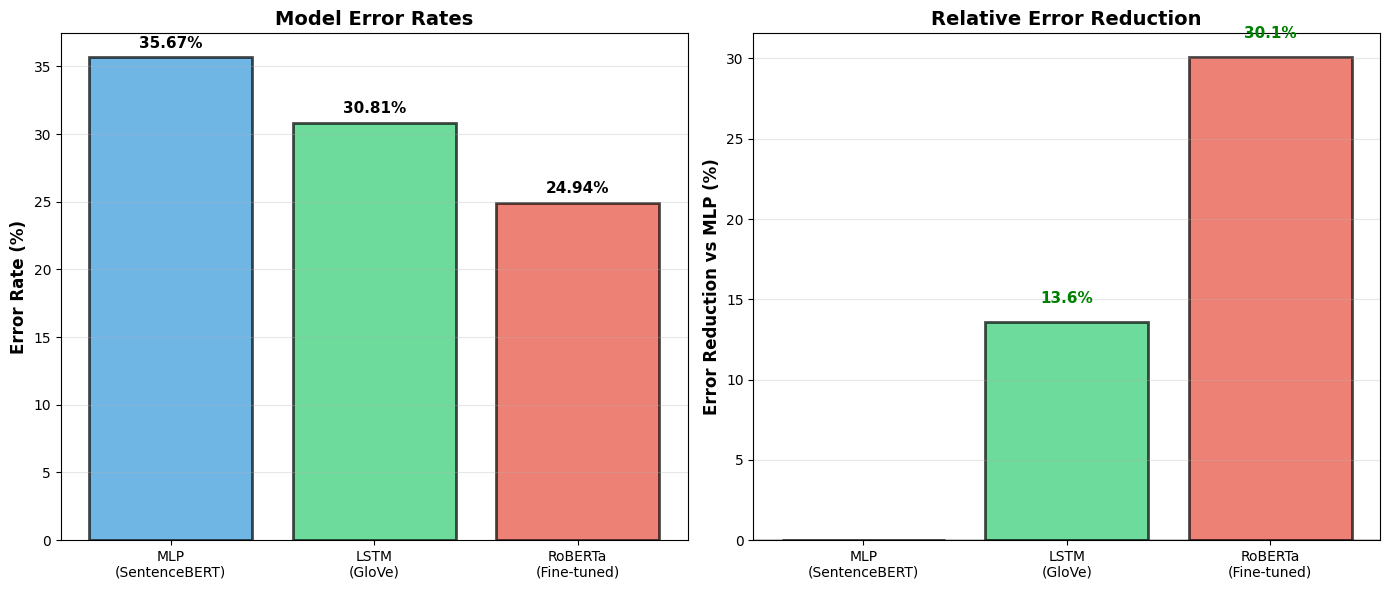

In [ ]:
# Visualization 1: Accuracy Comparison
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Left plot: Absolute accuracy
models = ['MLP\n(SentenceBERT)', 'LSTM\n(GloVe)', 'RoBERTa\n(Fine-tuned)']
accuracies = [mlp_acc, lstm_acc, roberta_acc]
colors = ['#3498db', '#2ecc71', '#e74c3c']

bars = ax1.bar(models, accuracies, color=colors, alpha=0.7, edgecolor='black', linewidth=2)
ax1.set_ylabel('Test Accuracy (%)', fontsize=12, fontweight='bold')
ax1.set_title('Model Performance Comparison', fontsize=14, fontweight='bold')
y_min = max(0, min(accuracies) - 10)
ax1.set_ylim([y_min, 100])
ax1.grid(True, alpha=0.3, axis='y')
ax1.axhline(y=50, color='gray', linestyle='--', alpha=0.5, label='Random baseline')

# Add value labels on bars
for bar, acc in zip(bars, accuracies):
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2., height + 1,
            f'{acc:.2f}%', ha='center', va='bottom', fontsize=11, fontweight='bold')

# Right plot: Improvement over MLP (baseline)
improvements = [0, lstm_acc - mlp_acc, roberta_acc - mlp_acc]
bars2 = ax2.bar(models, improvements, color=colors, alpha=0.7, edgecolor='black', linewidth=2)
ax2.set_ylabel('Accuracy Gain vs MLP (%)', fontsize=12, fontweight='bold')
ax2.set_title('Improvement Over Baseline (MLP)', fontsize=14, fontweight='bold')
ax2.grid(True, alpha=0.3, axis='y')
ax2.axhline(y=0, color='black', linestyle='-', linewidth=1)

# Add value labels
for bar, imp in zip(bars2, improvements):
    if imp > 0:
        height = bar.get_height()
        ax2.text(bar.get_x() + bar.get_width()/2., height + 0.2,
                f'+{imp:.2f}%', ha='center', va='bottom', fontsize=11, fontweight='bold', color='green')

plt.tight_layout()
plt.savefig('model_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

# Visualization 2: Model Complexity vs Performance
fig, ax = plt.subplots(figsize=(10, 6))

# Extract parameters (in millions)
params_mlp = sum(p.numel() for p in best_mlp.parameters()) / 1e6
params_lstm = trainable_params / 1e6
params_roberta = trainable_params_roberta / 1e6

params = [params_mlp, params_lstm, params_roberta]

scatter = ax.scatter(params, accuracies, s=500, c=colors, alpha=0.6, edgecolors='black', linewidth=2)
ax.set_xlabel('Trainable Parameters (Millions)', fontsize=12, fontweight='bold')
ax.set_ylabel('Test Accuracy (%)', fontsize=12, fontweight='bold')
ax.set_title('Model Complexity vs Performance', fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.3)

# Add labels
for i, model in enumerate(['MLP', 'LSTM', 'RoBERTa']):
    ax.annotate(model, (params[i], accuracies[i]),
                xytext=(10, 10), textcoords='offset points',
                fontsize=11, fontweight='bold')

plt.tight_layout()
plt.savefig('complexity_vs_performance.png', dpi=300, bbox_inches='tight')
plt.show()

# Visualization 3: Error Reduction Analysis
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Left: Error rates
error_rates = [100 - mlp_acc, 100 - lstm_acc, 100 - roberta_acc]
bars = ax1.bar(models, error_rates, color=colors, alpha=0.7, edgecolor='black', linewidth=2)
ax1.set_ylabel('Error Rate (%)', fontsize=12, fontweight='bold')
ax1.set_title('Model Error Rates', fontsize=14, fontweight='bold')
ax1.grid(True, alpha=0.3, axis='y')

# Add value labels
for bar, err in zip(bars, error_rates):
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2., height + 0.5,
            f'{err:.2f}%', ha='center', va='bottom', fontsize=11, fontweight='bold')

# Right: Relative error reduction
mlp_error = 100 - mlp_acc
error_reductions = [
    0,
    ((mlp_error - (100 - lstm_acc)) / mlp_error) * 100,
    ((mlp_error - (100 - roberta_acc)) / mlp_error) * 100
]
bars2 = ax2.bar(models, error_reductions, color=colors, alpha=0.7, edgecolor='black', linewidth=2)
ax2.set_ylabel('Error Reduction vs MLP (%)', fontsize=12, fontweight='bold')
ax2.set_title('Relative Error Reduction', fontsize=14, fontweight='bold')
ax2.grid(True, alpha=0.3, axis='y')
ax2.axhline(y=0, color='black', linestyle='-', linewidth=1)

# Add value labels
for bar, red in zip(bars2, error_reductions):
    if red > 0:
        height = bar.get_height()
        ax2.text(bar.get_x() + bar.get_width()/2., height + 1,
                f'{red:.1f}%', ha='center', va='bottom', fontsize=11, fontweight='bold', color='green')

plt.tight_layout()
plt.savefig('error_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
from google.colab import runtime
import time

print("Finalizing experiments and disconnecting...")
time.sleep(10)
runtime.unassign()
print("✓ GPU session ended - billing stopped")

Finalizing experiments and disconnecting...
✓ GPU session ended - billing stopped
